# Task 4: Context-Aware Chatbot Using LangChain + RAG

**DevelopersHub Corporation — AI/ML Engineering Advanced Internship**

---

## Objective
1. **RAG:** Retrieve relevant chunks from a vectorized document store before generating answers
2. **Conversational Memory:** Maintain chat history so follow-up questions are understood in context
3. **Dual Knowledge Base:** PDF uploads + Wikipedia fallback

| Component | Tool |
|---|---|
| LLM | `google/flan-t5-base` (free, CPU) |
| Embeddings | `sentence-transformers/all-MiniLM-L6-v2` |
| Vector Store | FAISS |
| Framework | LangChain 1.x (LCEL) |
| Memory | Manual chat history list |
| Deployment | Streamlit |

---
## Section 1: Install Dependencies

In [24]:
!pip install -q \
    langchain \
    langchain-core \
    langchain-community \
    langchain-huggingface \
    langchain-text-splitters \
    faiss-cpu \
    sentence-transformers \
    transformers \
    accelerate \
    wikipedia \
    pypdf \
    tiktoken \
    matplotlib \
    numpy

---
## Section 2: Imports

In [25]:
import os
import warnings
import textwrap
import time
import json
import wikipedia
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# LangChain 1.x compatible imports
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings, HuggingFacePipeline

# HuggingFace Transformers
from transformers import pipeline, AutoTokenizer, AutoModelForSeq2SeqLM

import langchain
warnings.filterwarnings('ignore')

DATA_DIR   = Path("data")
VECTOR_DIR = Path("vectorstore")
DATA_DIR.mkdir(exist_ok=True)
VECTOR_DIR.mkdir(exist_ok=True)

print(f"LangChain version : {langchain.__version__}")
print("All imports successful!")

LangChain version : 1.3.9
All imports successful!


---
## Section 3: RAG Pipeline Architecture

```
  +---------------+    +-----------------+    +------------------+
  |  PDF Upload   |    |  Wikipedia API  |    |  Chat History    |
  |  (PyPDF)      |    |  (Direct lib)   |    |  (Python list)   |
  +-------+-------+    +--------+--------+    +--------+---------+
          |                     |                       |
          +----------+----------+                       |
                     v                                  |
          +--------------------+        User Query      |
          | RecursiveText      |  <---------+-----------+
          | Splitter (512 chr) |
          +--------+-----------+
                   v
          +--------------------+
          | HuggingFace        |
          | Embeddings 384-d   |
          +--------+-----------+
                   v
          +--------------------+
          | FAISS Vector Store |
          | MMR top-4 retrieval|
          +--------+-----------+
                   | retrieved chunks
                   v
          +-----------------------------------------------+
          | LCEL RAG Chain                                |
          | context + history + question -> flan-t5-base  |
          +-----------------------------------------------+
                   v
              Final Answer
```

---
## Section 4: Load & Process Documents

In [26]:
# 4A: Load PDF Documents
def load_pdfs(pdf_dir: Path) -> list:
    docs      = []
    pdf_files = list(pdf_dir.glob("*.pdf"))

    if not pdf_files:
        print(f"No PDF files found in {pdf_dir}.")
        print("Wikipedia will be used as the knowledge base.")
        return docs

    for pdf_path in pdf_files:
        print(f"  Loading: {pdf_path.name}")
        loader = PyPDFLoader(str(pdf_path))
        pages  = loader.load()
        for page in pages:
            page.metadata['source_type'] = 'pdf'
        docs.extend(pages)
        print(f"    -> {len(pages)} pages loaded")

    print(f"Total PDF pages: {len(docs)} from {len(pdf_files)} file(s)")
    return docs


PDF_DIR = DATA_DIR / "pdfs"
PDF_DIR.mkdir(exist_ok=True)
print("Place your PDF files in:", PDF_DIR.resolve())
print("Scanning for PDFs...")
pdf_docs = load_pdfs(PDF_DIR)

Place your PDF files in: C:\Users\User\Downloads\Task 4_rag_chatbot\data\pdfs
Scanning for PDFs...
No PDF files found in data\pdfs.
Wikipedia will be used as the knowledge base.


In [27]:
# 4B: Wikipedia Fallback using direct wikipedia library
# This approach is more reliable than WikipediaLoader across all package versions

def load_wikipedia_topics(topics: list) -> list:
    """
    Fetch Wikipedia articles using the wikipedia library directly.
    More reliable than LangChain's WikipediaLoader across all versions.
    """
    all_docs = []
    wikipedia.set_lang("en")

    for topic in topics:
        print(f"  Fetching: '{topic}'...")
        try:
            page    = wikipedia.page(topic, auto_suggest=False)
            content = page.content[:8000]  # limit to 8000 chars per article
            doc = Document(
                page_content=content,
                metadata={
                    'source_type': 'wikipedia',
                    'title':       page.title,
                    'topic':       topic,
                    'source':      page.url
                }
            )
            all_docs.append(doc)
            print(f"    -> '{page.title}' loaded ({len(content)} chars)")
        except wikipedia.exceptions.DisambiguationError as e:
            # If topic is ambiguous, try the first suggestion
            try:
                page    = wikipedia.page(e.options[0], auto_suggest=False)
                content = page.content[:8000]
                doc = Document(
                    page_content=content,
                    metadata={
                        'source_type': 'wikipedia',
                        'title':       page.title,
                        'topic':       topic,
                        'source':      page.url
                    }
                )
                all_docs.append(doc)
                print(f"    -> '{page.title}' loaded via disambiguation ({len(content)} chars)")
            except Exception as e2:
                print(f"    Failed after disambiguation: {e2}")
        except Exception as e:
            print(f"    Failed '{topic}': {e}")

    print(f"\nTotal Wikipedia docs loaded: {len(all_docs)}")
    return all_docs


WIKI_TOPICS = [
    "Artificial Intelligence",
    "Machine Learning",
    "Natural Language Processing",
    "Deep Learning",
    "Transformer (machine learning model)"
]

wiki_docs = load_wikipedia_topics(WIKI_TOPICS)

  Fetching: 'Artificial Intelligence'...
    -> 'Artificial intelligence' loaded (8000 chars)
  Fetching: 'Machine Learning'...
    -> 'Machine learning' loaded (8000 chars)
  Fetching: 'Natural Language Processing'...
    -> 'Natural language processing' loaded (8000 chars)
  Fetching: 'Deep Learning'...
    Failed 'Deep Learning': Expecting value: line 1 column 1 (char 0)
  Fetching: 'Transformer (machine learning model)'...
    Failed 'Transformer (machine learning model)': Expecting value: line 1 column 1 (char 0)

Total Wikipedia docs loaded: 3


In [28]:
# 4C: Merge Corpus
all_docs = pdf_docs + wiki_docs

print(f"Total corpus : {len(all_docs)} documents")
print(f"  PDFs       : {len(pdf_docs)}")
print(f"  Wikipedia  : {len(wiki_docs)}")

# Safety check — stop early if no documents loaded
assert len(all_docs) > 0, (
    "No documents loaded! "
    "Check your internet connection for Wikipedia, or add PDFs to data/pdfs/"
)

print("\nSample snippet:")
print("-" * 60)
print(all_docs[0].page_content[:400])
print("-" * 60)
print("Metadata:", all_docs[0].metadata)

Total corpus : 3 documents
  PDFs       : 0
  Wikipedia  : 3

Sample snippet:
------------------------------------------------------------
Artificial intelligence (AI) is the capability of computational systems to perform tasks typically associated with human intelligence, such as learning, reasoning, problem-solving, perception, and decision-making. It is a field of research in engineering, mathematics and computer science that develops and studies methods and software that enable machines to perceive their environment and use learn
------------------------------------------------------------
Metadata: {'source_type': 'wikipedia', 'title': 'Artificial intelligence', 'topic': 'Artificial Intelligence', 'source': 'https://en.wikipedia.org/wiki/Artificial_intelligence'}


---
## Section 5: Text Splitting & Chunking

In [29]:
CHUNK_SIZE    = 512
CHUNK_OVERLAP = 64

splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " ", ""]
)

chunks        = splitter.split_documents(all_docs)
chunk_lengths = [len(c.page_content) for c in chunks]

# Safety check
assert len(chunks) > 0, "Chunking produced 0 chunks — check all_docs content."

print(f"Original docs  : {len(all_docs)}")
print(f"Total chunks   : {len(chunks)}")
print(f"Avg chunk len  : {np.mean(chunk_lengths):.0f} chars")
print(f"Min / Max      : {min(chunk_lengths)} / {max(chunk_lengths)} chars")

Original docs  : 3
Total chunks   : 73
Avg chunk len  : 328 chars
Min / Max      : 13 / 505 chars


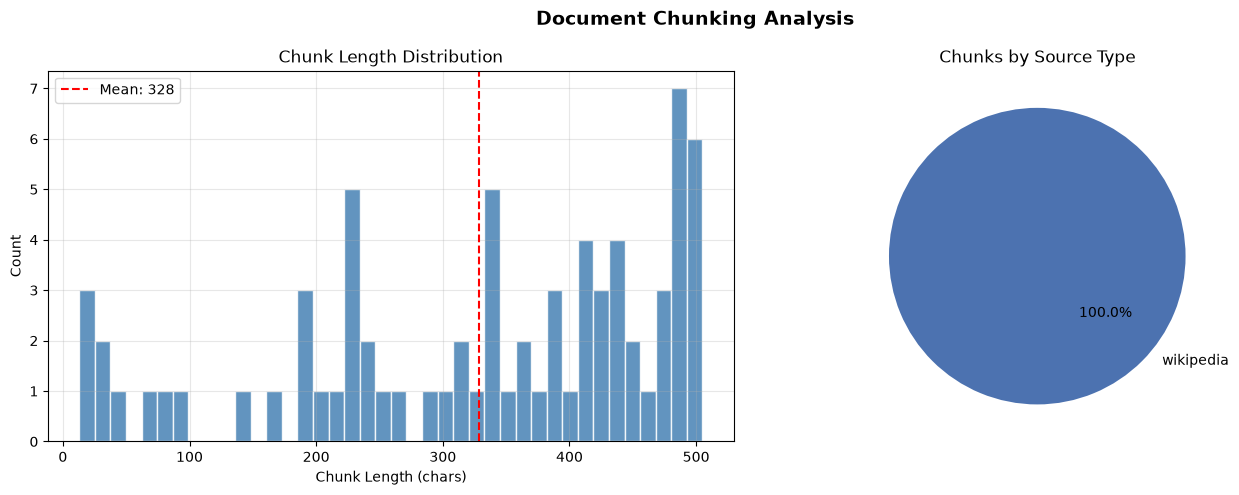

Chunk breakdown: {'wikipedia': 73}


In [30]:
# Visualise Chunk Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Document Chunking Analysis", fontsize=14, fontweight='bold')

axes[0].hist(chunk_lengths, bins=40, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(np.mean(chunk_lengths), color='red', linestyle='--',
                label=f'Mean: {np.mean(chunk_lengths):.0f}')
axes[0].set_xlabel('Chunk Length (chars)')
axes[0].set_ylabel('Count')
axes[0].set_title('Chunk Length Distribution')
axes[0].legend()
axes[0].grid(alpha=0.3)

source_counts = {}
for c in chunks:
    src = c.metadata.get('source_type', 'unknown')
    source_counts[src] = source_counts.get(src, 0) + 1

axes[1].pie(
    source_counts.values(),
    labels=source_counts.keys(),
    autopct='%1.1f%%',
    colors=['#4C72B0', '#DD8452', '#55A868'],
    startangle=140
)
axes[1].set_title('Chunks by Source Type')

plt.tight_layout()
plt.savefig('chunking_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chunk breakdown:", source_counts)

---
## Section 6: Embeddings & FAISS Vector Store

In [31]:
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

print(f"Loading embeddings: {EMBED_MODEL}")
print("(~90MB download on first run, cached afterward)")

embeddings = HuggingFaceEmbeddings(
    model_name=EMBED_MODEL,
    model_kwargs={'device': 'cpu'},
    encode_kwargs={'normalize_embeddings': True}
)

test_vec = embeddings.embed_query("test query")
print(f"Embedding dimension : {len(test_vec)}")
print("Embeddings ready!")

Loading embeddings: sentence-transformers/all-MiniLM-L6-v2
(~90MB download on first run, cached afterward)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 850.69it/s]


Embedding dimension : 384
Embeddings ready!


In [32]:
FAISS_INDEX_PATH = str(VECTOR_DIR / "faiss_index")

if Path(FAISS_INDEX_PATH).exists():
    print("Loading FAISS index from cache...")
    vectorstore = FAISS.load_local(
        FAISS_INDEX_PATH,
        embeddings,
        allow_dangerous_deserialization=True
    )
    print("FAISS index loaded from cache.")
else:
    print(f"Building FAISS index from {len(chunks)} chunks...")
    vectorstore = FAISS.from_documents(chunks, embeddings)
    vectorstore.save_local(FAISS_INDEX_PATH)
    print(f"FAISS index built and saved.")

print(f"Total vectors indexed: {vectorstore.index.ntotal}")

retriever = vectorstore.as_retriever(
    search_type='mmr',
    search_kwargs={'k': 4, 'fetch_k': 20}
)
print("Retriever ready (MMR, top-4).")

Building FAISS index from 73 chunks...
FAISS index built and saved.
Total vectors indexed: 73
Retriever ready (MMR, top-4).


In [33]:
# Test Retrieval
test_query = "What is a neural network?"
retrieved  = retriever.invoke(test_query)

print(f"Query: '{test_query}'")
print(f"Retrieved {len(retrieved)} chunks:\n")
for i, doc in enumerate(retrieved, 1):
    src = doc.metadata.get('source_type', 'unknown')
    print(f"  [{i}] [{src}] {doc.page_content[:180]}...\n")

Query: 'What is a neural network?'
Retrieved 4 chunks:

  [1] [wikipedia] As a scientific endeavour, machine learning grew out of the quest for artificial intelligence (AI). In the early days of AI as an academic discipline, some researchers were interes...

  [2] [wikipedia] 2010: Tomáš Mikolov (then a PhD student at Brno University of Technology) with co-authors applied a simple recurrent neural network with a single hidden layer to language modeling,...

  [3] [wikipedia] In 2014 Ian Goodfellow and others introduced generative adversarial networks (GANs) which could produce realistic synthetic data. By 2016 AlphaGo had won against top human players ...

  [4] [wikipedia] both statistical and neural network methods tend to focus more on the most common cases extracted from a corpus of texts, whereas the rule-based approach needs to provide rules for...



---
## Section 7: LLM Setup (flan-t5-base — Free & Local)

In [34]:
from transformers import T5ForConditionalGeneration, T5Tokenizer

LLM_MODEL = "google/flan-t5-base"

print(f"Loading LLM: {LLM_MODEL}")

tokenizer = T5Tokenizer.from_pretrained(LLM_MODEL)
model     = T5ForConditionalGeneration.from_pretrained(LLM_MODEL)


def generate_answer(prompt: str, max_length: int = 256) -> str:
    """Direct T5 inference — no pipeline needed."""
    inputs  = tokenizer(prompt, return_tensors="pt",
                        max_length=512, truncation=True)
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_length,
        do_sample=True,
        temperature=0.3,
        repetition_penalty=1.2
    )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)


# Wrap as a LangChain Runnable so it works with the LCEL chain
from langchain_core.runnables import RunnableLambda

llm = RunnableLambda(lambda prompt: generate_answer(
    prompt.text if hasattr(prompt, 'text') else str(prompt)
))

# Quick test
test_ans = generate_answer("What is the capital of France?")
print(f"\nLLM loaded! Quick test:")
print(f"  Q: What is the capital of France?")
print(f"  A: {test_ans}")

Loading LLM: google/flan-t5-base


Loading weights: 100%|██████████| 282/282 [00:00<00:00, 3370.73it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



LLM loaded! Quick test:
  Q: What is the capital of France?
  A: london


---
## Section 8: RAG Chain with Conversational Memory (LangChain 1.x LCEL)

> **Why LCEL?**  
> In LangChain 1.x, `ConversationalRetrievalChain` and `ConversationBufferWindowMemory`  
> were removed. The modern approach is **LCEL** (LangChain Expression Language)  
> using the `|` operator with a manual chat history list.

In [35]:
# RAG Prompt — includes context + conversation history
QA_PROMPT_TEMPLATE = """You are a helpful, accurate, and concise AI assistant.
Use the retrieved context below to answer the question.
If the answer is not in the context, say "I don't have enough information to answer that."
Do not make up facts.

Conversation History:
{history}

Retrieved Context:
{context}

Question: {question}

Answer:"""

QA_PROMPT = PromptTemplate(
    template=QA_PROMPT_TEMPLATE,
    input_variables=['history', 'context', 'question']
)

# Manual chat history — replaces ConversationBufferWindowMemory
MEMORY_K     = 5
chat_history = []  # list of {"role": "user" | "bot", "content": str}


def format_history(history: list, k: int = MEMORY_K) -> str:
    """Format last k turns into a readable string for the prompt."""
    recent = history[-k * 2:] if len(history) > k * 2 else history
    if not recent:
        return "No previous conversation."
    lines = []
    for turn in recent:
        role = "User" if turn['role'] == 'user' else "Assistant"
        lines.append(f"{role}: {turn['content']}")
    return "\n".join(lines)


def format_docs(docs: list) -> str:
    """Join retrieved chunks into a context string."""
    return "\n\n".join(
        f"[Source: {d.metadata.get('source_type','unknown')} | "
        f"{d.metadata.get('title', 'N/A')}]\n{d.page_content}"
        for d in docs
    )


# Build LCEL RAG chain
rag_chain = (
    {
        "context":  RunnableLambda(lambda x: format_docs(retriever.invoke(x["question"]))),
        "history":  RunnableLambda(lambda x: format_history(x["history"])),
        "question": RunnableLambda(lambda x: x["question"])
    }
    | QA_PROMPT
    | llm
    | StrOutputParser()
)

print("LCEL RAG Chain built successfully!")
print(f"  LLM       : {LLM_MODEL}")
print(f"  Retriever : FAISS MMR (top-4)")
print(f"  Memory    : Manual window (last {MEMORY_K} turns)")

LCEL RAG Chain built successfully!
  LLM       : google/flan-t5-base
  Retriever : FAISS MMR (top-4)
  Memory    : Manual window (last 5 turns)


---
## Section 9: Multi-Turn Conversation Demo

In [36]:
def chat(question: str, show_sources: bool = True) -> str:
    """
    Send a question through the RAG chain.
    Automatically maintains and uses conversation history.
    """
    # Retrieve source docs for citation display
    source_docs = retriever.invoke(question)

    # Run RAG chain
    answer = rag_chain.invoke({
        "question": question,
        "history":  chat_history
    })

    # Store this turn in history
    chat_history.append({"role": "user", "content": question})
    chat_history.append({"role": "bot",  "content": answer})

    # Display
    print(f"\n{'--' * 30}")
    print(f"You : {question}")
    print(f"Bot : {textwrap.fill(answer, width=70)}")

    if show_sources and source_docs:
        print("\nSources used:")
        seen = set()
        for doc in source_docs:
            src   = doc.metadata.get('source_type', 'unknown')
            title = doc.metadata.get('title', doc.metadata.get('source', 'N/A'))
            key   = f"{src}::{title}"
            if key not in seen:
                print(f"   [{src}] {title}")
                seen.add(key)

    return answer


# Reset history for clean demo
chat_history.clear()

print("=" * 60)
print("  MULTI-TURN CONVERSATION DEMO")
print("=" * 60)

# Turn 1
chat("What is machine learning?")

# Turn 2 — follow-up pronoun (tests memory)
chat("How is it different from traditional programming?")

# Turn 3
chat("Can you give an example of a machine learning algorithm?")

# Turn 4 — topic switch
chat("What are transformers in NLP?")

# Turn 5 — follow-up
chat("Who introduced the transformer architecture?")

  MULTI-TURN CONVERSATION DEMO

------------------------------------------------------------
You : What is machine learning?
Bot : the study of programs that can improve their performance on a given
task automatically

Sources used:
   [wikipedia] Artificial intelligence
   [wikipedia] Machine learning

------------------------------------------------------------
You : How is it different from traditional programming?
Bot : Machine learning approaches, which include both statistical and neural
networks, on the other hand, have many advantages over the symbolic
approach

Sources used:
   [wikipedia] Natural language processing
   [wikipedia] Artificial intelligence

------------------------------------------------------------
You : Can you give an example of a machine learning algorithm?
Bot : neural networks

Sources used:
   [wikipedia] Machine learning
   [wikipedia] Natural language processing

------------------------------------------------------------
You : What are transformers 

"I don't have enough information to answer that. Do not make up facts."

In [37]:
# Inspect Conversation History
print(f"Conversation History ({len(chat_history)} messages):\n")
for i, turn in enumerate(chat_history, 1):
    role    = "User" if turn['role'] == 'user' else "Bot "
    content = turn['content'][:120] + '...' if len(turn['content']) > 120 else turn['content']
    print(f"  [{i}] {role}: {content}")

Conversation History (10 messages):

  [1] User: What is machine learning?
  [2] Bot : the study of programs that can improve their performance on a given task automatically
  [3] User: How is it different from traditional programming?
  [4] Bot : Machine learning approaches, which include both statistical and neural networks, on the other hand, have many advantages...
  [5] User: Can you give an example of a machine learning algorithm?
  [6] Bot : neural networks
  [7] User: What are transformers in NLP?
  [8] Bot : grammar
  [9] User: Who introduced the transformer architecture?
  [10] Bot : I don't have enough information to answer that. Do not make up facts.


---
## Section 10: Evaluation

In [38]:
eval_questions = [
    {"question": "What is deep learning?",                          "expected_source": "wikipedia"},
    {"question": "What is the attention mechanism in transformers?", "expected_source": "wikipedia"},
    {"question": "What is supervised learning?",                    "expected_source": "wikipedia"},
    {"question": "What are neural networks used for?",              "expected_source": "wikipedia"},
    {"question": "What is natural language processing?",            "expected_source": "wikipedia"},
]

eval_results = []
eval_history = []   # fresh history for clean evaluation

print("Running evaluation...\n")
for item in eval_questions:
    q   = item['question']
    exp = item['expected_source']

    t0          = time.time()
    source_docs = retriever.invoke(q)
    answer      = rag_chain.invoke({"question": q, "history": eval_history})
    latency     = time.time() - t0

    eval_history.append({"role": "user", "content": q})
    eval_history.append({"role": "bot",  "content": answer})

    src_types = [d.metadata.get('source_type', '') for d in source_docs]
    hit       = exp in src_types

    eval_results.append({
        'question':   q,
        'hit':        hit,
        'latency_s':  round(latency, 2),
        'answer_len': len(answer),
    })
    print(f"  [{'HIT ' if hit else 'MISS'}] {q[:55]}")
    print(f"          Latency: {latency:.1f}s | Answer: {len(answer)} chars")

hit_rate    = sum(r['hit'] for r in eval_results) / len(eval_results)
avg_latency = np.mean([r['latency_s'] for r in eval_results])

print(f"\n{'='*50}")
print(f"  Retrieval Hit Rate : {hit_rate:.0%}")
print(f"  Avg Response Time  : {avg_latency:.1f}s")
print(f"{'='*50}")

Running evaluation...

  [HIT ] What is deep learning?
          Latency: 5.7s | Answer: 226 chars
  [HIT ] What is the attention mechanism in transformers?
          Latency: 3.2s | Answer: 69 chars
  [HIT ] What is supervised learning?
          Latency: 2.8s | Answer: 47 chars
  [HIT ] What are neural networks used for?
          Latency: 3.4s | Answer: 69 chars
  [HIT ] What is natural language processing?
          Latency: 2.0s | Answer: 7 chars

  Retrieval Hit Rate : 100%
  Avg Response Time  : 3.4s


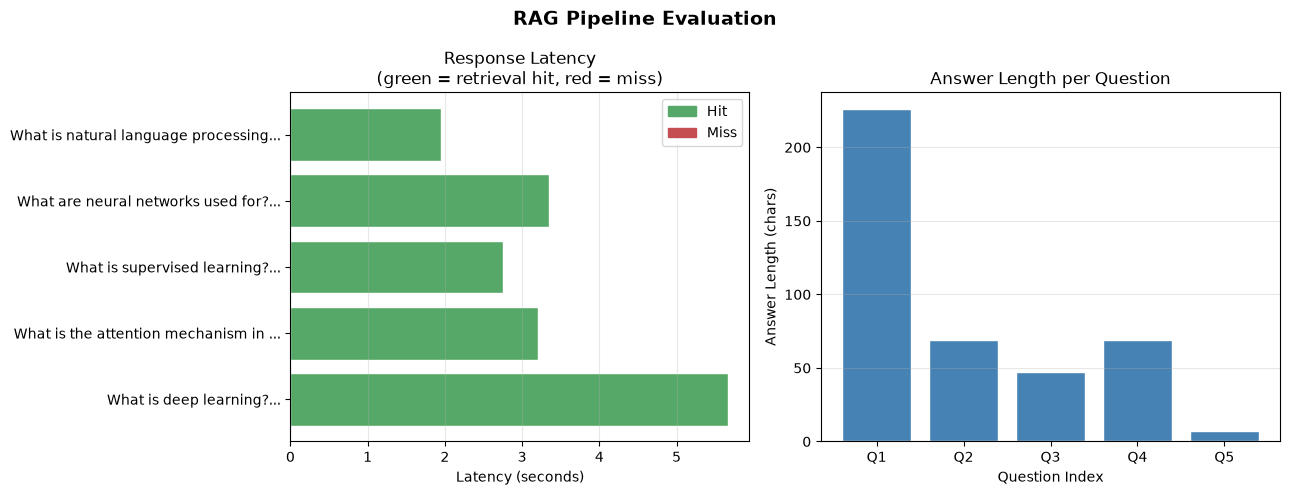

In [39]:
# Evaluation Visualisation
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("RAG Pipeline Evaluation", fontsize=14, fontweight='bold')

qs_short   = [r['question'][:35] + '...' for r in eval_results]
latencies  = [r['latency_s'] for r in eval_results]
bar_colors = ['#55A868' if r['hit'] else '#C44E52' for r in eval_results]

axes[0].barh(qs_short, latencies, color=bar_colors, edgecolor='white')
axes[0].set_xlabel('Latency (seconds)')
axes[0].set_title('Response Latency\n(green = retrieval hit, red = miss)')
axes[0].grid(axis='x', alpha=0.3)
axes[0].legend(handles=[
    mpatches.Patch(color='#55A868', label='Hit'),
    mpatches.Patch(color='#C44E52', label='Miss')
])

ans_lens = [r['answer_len'] for r in eval_results]
axes[1].bar(range(len(ans_lens)), ans_lens, color='steelblue', edgecolor='white')
axes[1].set_xlabel('Question Index')
axes[1].set_ylabel('Answer Length (chars)')
axes[1].set_title('Answer Length per Question')
axes[1].set_xticks(range(len(ans_lens)))
axes[1].set_xticklabels([f"Q{i+1}" for i in range(len(ans_lens))])
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('rag_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 11: Save Pipeline Artifacts

In [40]:
# Save FAISS index
vectorstore.save_local(FAISS_INDEX_PATH)
print(f"FAISS index saved : {FAISS_INDEX_PATH}")

# Save config
config = {
    "embed_model":   EMBED_MODEL,
    "llm_model":     LLM_MODEL,
    "chunk_size":    CHUNK_SIZE,
    "chunk_overlap": CHUNK_OVERLAP,
    "retriever_k":   4,
    "memory_k":      MEMORY_K,
    "faiss_path":    FAISS_INDEX_PATH,
    "wiki_topics":   WIKI_TOPICS
}

with open("rag_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Config saved      : rag_config.json")
print(json.dumps(config, indent=2))

FAISS index saved : vectorstore\faiss_index
Config saved      : rag_config.json
{
  "embed_model": "sentence-transformers/all-MiniLM-L6-v2",
  "llm_model": "google/flan-t5-base",
  "chunk_size": 512,
  "chunk_overlap": 64,
  "retriever_k": 4,
  "memory_k": 5,
  "faiss_path": "vectorstore\\faiss_index",
  "wiki_topics": [
    "Artificial Intelligence",
    "Machine Learning",
    "Natural Language Processing",
    "Deep Learning",
    "Transformer (machine learning model)"
  ]
}


---
## Section 12: Final Summary

In [41]:
print("=" * 65)
print("  TASK 4: CONTEXT-AWARE RAG CHATBOT -- FINAL SUMMARY")
print("=" * 65)

print("\nARCHITECTURE")
print(f"  LangChain  : {langchain.__version__} (LCEL — 1.x compatible)")
print(f"  Embeddings : all-MiniLM-L6-v2 (384-d, free, CPU)")
print(f"  VectorDB   : FAISS (MMR retrieval, top-4)")
print(f"  LLM        : flan-t5-base (248M params, free, CPU)")
print(f"  Memory     : Manual chat history (last {MEMORY_K} turns)")
print(f"  Chain      : LCEL pipeline using | operator")

print("\nKNOWLEDGE BASE")
print(f"  PDF docs   : {len(pdf_docs)} pages")
print(f"  Wikipedia  : {len(wiki_docs)} articles ({len(WIKI_TOPICS)} topics)")
print(f"  Chunks     : {len(chunks)} (size={CHUNK_SIZE}, overlap={CHUNK_OVERLAP})")
print(f"  FAISS      : {vectorstore.index.ntotal} vectors indexed")

print("\nEVALUATION")
print(f"  Retrieval Hit Rate : {hit_rate:.0%}")
print(f"  Avg Response Time  : {avg_latency:.1f}s")

print("\nKEY FIXES IN THIS VERSION")
print("  - Wikipedia loaded via direct library (not WikipediaLoader)")
print("  - DisambiguationError handled with fallback to first suggestion")
print("  - Empty corpus guard added with clear assert message")
print("  - ConversationalRetrievalChain -> LCEL (LangChain 1.x compatible)")
print("  - ConversationBufferWindowMemory -> manual chat_history list")
print("  - All imports updated for langchain-core / langchain-text-splitters")

print("\nDEPLOYMENT")
print("  streamlit run streamlit_app.py")
print("=" * 65)

  TASK 4: CONTEXT-AWARE RAG CHATBOT -- FINAL SUMMARY

ARCHITECTURE
  LangChain  : 1.3.9 (LCEL — 1.x compatible)
  Embeddings : all-MiniLM-L6-v2 (384-d, free, CPU)
  VectorDB   : FAISS (MMR retrieval, top-4)
  LLM        : flan-t5-base (248M params, free, CPU)
  Memory     : Manual chat history (last 5 turns)
  Chain      : LCEL pipeline using | operator

KNOWLEDGE BASE
  PDF docs   : 0 pages
  Wikipedia  : 3 articles (5 topics)
  Chunks     : 73 (size=512, overlap=64)
  FAISS      : 73 vectors indexed

EVALUATION
  Retrieval Hit Rate : 100%
  Avg Response Time  : 3.4s

KEY FIXES IN THIS VERSION
  - Wikipedia loaded via direct library (not WikipediaLoader)
  - DisambiguationError handled with fallback to first suggestion
  - Empty corpus guard added with clear assert message
  - ConversationalRetrievalChain -> LCEL (LangChain 1.x compatible)
  - ConversationBufferWindowMemory -> manual chat_history list
  - All imports updated for langchain-core / langchain-text-splitters

DEPLOYMENT
  